# Despliegue - Predicción de cancelaciones de reservas hoteleras

Variable objetivo: **is_canceled** (1 = reserva cancelada, 0 = no cancelada)

1. Cargar el modelo final (Pipe)
2. Verificación del Pipe con el 30% de prueba
3. Funciones de la interfaz
4. Datos de apoyo para la interfaz
5. Interfaz gráfica con Streamlit
6. Ejecutar la interfaz

*Nota:* este notebook usa el archivo modelo_hotel_bookings.pkl del notebook de modelos y hotel_bookings_preparado.csv del notebook de preparación. La interfaz solo necesita modelo_hotel_bookings.pkl y despliegue_config.json.

In [1]:
#Librerías
import pickle
import json
import itertools
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import metrics

import warnings
warnings.simplefilter("ignore")

# 1. Cargar el modelo final (Pipe)

El Pipe contiene la preparación de los datos (normalización, dummies y agrupación de países) y el modelo, por lo que recibe una reserva con sus valores originales.

In [2]:
#Se carga el Pipe del modelo final (preparación de los datos + XGBoost ajustado con optimización bayesiana)
pipe = pickle.load(open('modelo_hotel_bookings.pkl', 'rb'))
pipe

Pipeline(steps=[('preparacion',
                 ColumnTransformer(transformers=[('numericas', MinMaxScaler(),
                                                  ['lead_time', 'adults',
                                                   'previous_cancellations',
                                                   'previous_bookings_not_canceled',
                                                   'booking_changes',
                                                   'days_in_waiting_list',
                                                   'required_car_parking_spaces',
                                                   'total_of_special_requests']),
                                                 ('paises',
                                                  OneHotEncoder(categories=[['AUT',
                                                                             'BEL',
                                                                             'BRA',
                                                                             'CHE',
                                                                             'CHN',
                                                                             'CN',
                                                                             'DEU',...
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.17396068310086973, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=7,
                               max_leaves=None, min_child_weight=None,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=482, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [3]:
#Variables que recibe el Pipe: las 17 predictoras originales, sin dummies ni normalización
list(pipe.feature_names_in_)

['hotel',
 'lead_time',
 'arrival_date_month',
 'adults',
 'country',
 'market_segment',
 'distribution_channel',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'reserved_room_type',
 'booking_changes',
 'deposit_type',
 'days_in_waiting_list',
 'customer_type',
 'required_car_parking_spaces',
 'total_of_special_requests']

# 2. Verificación del Pipe con el 30% de prueba

No se entrena ningún modelo: se repite la división 70-30 del notebook de modelos solo para confirmar que el Pipe guardado entrega los mismos resultados y para tomar del 70% las categorías del formulario.

In [4]:
#Datos preparados y la misma división 70-30 del notebook de modelos (estratificada, random_state=42)
data = pd.read_csv("hotel_bookings_preparado.csv")
objetivo = 'is_canceled'
predictoras_numericas = ['lead_time', 'adults', 'previous_cancellations', 'previous_bookings_not_canceled',
                         'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']
predictoras_categoricas = ['hotel', 'is_repeated_guest', 'arrival_date_month', 'country', 'market_segment',
                           'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
for variable in predictoras_categoricas:
    data[variable] = data[variable].astype(str)

X = data.drop(objetivo, axis=1)
Y = data[objetivo]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42)
print(X_train.shape, X_test.shape)

(83447, 17) (35763, 17)


In [5]:
#Verificación: el Pipe cargado reproduce la evaluación del 30% del notebook de modelos
Y_pred = pipe.predict(X_test)
print("F1 macro:", round(metrics.f1_score(Y_test, Y_pred, average='macro'), 4))
print("Accuracy:", round(metrics.accuracy_score(Y_test, Y_pred), 4))

F1 macro:

 0.8462
Accuracy: 0.8588


# 3. Funciones de la interfaz

Toda reserva recibe una de tres respuestas:

1. **Datos incoherentes**: reglas lógicas entre los datos (fechas, lista de espera frente a anticipación, parqueaderos frente a adultos).
2. **Sin datos suficientes**: la reserva no se parece a las reservas históricas (combinación de hotel, origen, canal, depósito y tipo de reserva con menos de 20 reservas, categoría con menos de 20 reservas, valor numérico mayor que lo observado o par de datos con menos de 3 reservas). No se da veredicto, pero sí recomendaciones basadas en tasas históricas.
3. **Estimación**: probabilidad, razones en lenguaje sencillo (aporte de cada variable en XGBoost) y sugerencias para evitar la cancelación.

In [6]:
%%writefile utilidades_despliegue.py
#Funciones de apoyo de la interfaz: predicción, razones en lenguaje sencillo y sugerencias para evitar la cancelación
import json
import pickle

import pandas as pd
import xgboost as xgb

#Nombres en español de las categorías (los valores originales que recibe el modelo no cambian)
ETIQUETAS = {
    'hotel': {'City Hotel': 'Hotel de ciudad (Lisboa)', 'Resort Hotel': 'Hotel resort (Algarve)'},
    'arrival_date_month': {'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril', 'May': 'Mayo',
                           'June': 'Junio', 'July': 'Julio', 'August': 'Agosto', 'September': 'Septiembre',
                           'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'},
    'market_segment': {'Online TA': 'Agencia de viajes en línea', 'Offline TA/TO': 'Agencia u operador tradicional',
                       'Groups': 'Grupo', 'Direct': 'Directa con el hotel', 'Corporate': 'Empresa (corporativa)',
                       'Complementary': 'Cortesía del hotel', 'Aviation': 'Aerolínea'},
    'distribution_channel': {'TA/TO': 'Agencia u operador turístico', 'Direct': 'Directo con el hotel',
                             'Corporate': 'Convenio corporativo', 'GDS': 'Sistema global de reservas (GDS)'},
    'deposit_type': {'No Deposit': 'Sin depósito', 'Non Refund': 'Depósito no reembolsable',
                     'Refundable': 'Depósito reembolsable'},
    'customer_type': {'Transient': 'Individual', 'Transient-Party': 'Individual ligada a otra reserva',
                      'Group': 'Grupo', 'Contract': 'Contrato'},
    'country': {'PRT': 'Portugal', 'GBR': 'Reino Unido', 'FRA': 'Francia', 'ESP': 'España', 'DEU': 'Alemania',
                'ITA': 'Italia', 'IRL': 'Irlanda', 'BEL': 'Bélgica', 'BRA': 'Brasil', 'NLD': 'Países Bajos',
                'USA': 'Estados Unidos', 'CHE': 'Suiza', 'AUT': 'Austria', 'CN': 'China (CN)', 'CHN': 'China (CHN)',
                'SWE': 'Suecia', 'POL': 'Polonia', 'ISR': 'Israel', 'RUS': 'Rusia', 'NOR': 'Noruega',
                'Otros': 'Otro país'}}

MESES = list(ETIQUETAS['arrival_date_month'])  #orden del calendario
NOMBRES = {'hotel': 'Hotel', 'lead_time': 'Anticipación', 'arrival_date_month': 'Mes de llegada', 'adults': 'Adultos',
           'country': 'País', 'market_segment': 'Origen de la reserva', 'distribution_channel': 'Canal de venta',
           'is_repeated_guest': 'Huésped repetido', 'previous_cancellations': 'Reservas canceladas antes',
           'previous_bookings_not_canceled': 'Reservas cumplidas antes', 'reserved_room_type': 'Tipo de habitación',
           'booking_changes': 'Cambios a la reserva', 'deposit_type': 'Depósito',
           'days_in_waiting_list': 'Días en lista de espera', 'customer_type': 'Tipo de reserva',
           'required_car_parking_spaces': 'Parqueaderos', 'total_of_special_requests': 'Solicitudes especiales'}
MINIMO = 0.15  #aporte mínimo (escala del modelo) para mencionar una variable como razón


def cargar(ruta_modelo='modelo_hotel_bookings.pkl', ruta_config='despliegue_config.json'):
    pipe = pickle.load(open(ruta_modelo, 'rb'))
    config = json.load(open(ruta_config, encoding='utf-8'))
    return pipe, config


def etiqueta(variable, valor):
    return ETIQUETAS.get(variable, {}).get(str(valor), str(valor))


def plural(n, singular, varios):
    return f'{n} {singular if n == 1 else varios}'


def preparar(reservas, config):
    """Deja las reservas con las 17 variables, el orden y los tipos con los que se entrenó el Pipe."""
    X = reservas[config['variables']].copy()
    for variable in config['variables']:
        if variable in config['numericas']:
            X[variable] = pd.to_numeric(X[variable]).astype(int)
        else:
            X[variable] = X[variable].astype(str).str.strip()
    return X


def porcentaje(probabilidad):
    """Probabilidad para el usuario, sin mostrar 0% o 100% como si fueran certezas."""
    if probabilidad < 0.01:
        return 'menos de 1%'
    if probabilidad > 0.99:
        return 'más de 99%'
    return f'{probabilidad:.0%}'


def resultado(probabilidad, umbral):
    """Veredicto para el usuario: alto desde el umbral del modelo, moderado desde la mitad del umbral."""
    if probabilidad >= umbral:
        return 'alto'
    return 'moderado' if probabilidad >= umbral / 2 else 'bajo'


def aportes(pipe, X1):
    """Aporte de cada variable original a la predicción de una reserva (contribuciones de XGBoost)."""
    preparacion = pipe.named_steps['preparacion']
    Z = preparacion.transform(X1)
    valores = pipe.named_steps['modelo'].get_booster().predict(xgb.DMatrix(Z), pred_contribs=True)[0]
    columnas = [nombre.split('__', 1)[1] for nombre in preparacion.get_feature_names_out()]
    variables = list(X1.columns)
    suma = dict.fromkeys(variables, 0.0)
    for columna, valor in zip(columnas, valores[:-1]):
        #cada dummy se suma a su variable original (ej. deposit_type_Non Refund -> deposit_type)
        variable = max((v for v in variables if columna == v or columna.startswith(v + '_')), key=len)
        suma[variable] += float(valor)
    return pd.Series(suma).sort_values(key=abs, ascending=False)


def frase(variable, valor):
    """Describe en palabras el dato de la reserva que influye en el resultado."""
    v = valor
    if variable == 'lead_time':
        return f'Se reservó con {plural(v, "día", "días")} de anticipación'
    if variable == 'arrival_date_month':
        return f'La llegada es en {etiqueta(variable, v).lower()}'
    if variable == 'adults':
        return f'La reserva es para {plural(v, "adulto", "adultos")}'
    if variable == 'hotel':
        return f'Es una reserva en el {etiqueta(variable, v).split(" (")[0].lower()}'
    if variable == 'country':
        return 'El cliente es de un país con pocas reservas en el hotel' if v == 'Otros' else f'El cliente es de {etiqueta(variable, v)}'
    if variable == 'market_segment':
        return f'Origen de la reserva: {etiqueta(variable, v).lower()}'
    if variable == 'distribution_channel':
        return f'Se vendió por: {etiqueta(variable, v).lower()}'
    if variable == 'previous_cancellations':
        return 'El cliente no tiene cancelaciones anteriores' if v == 0 else f'El cliente ha cancelado {plural(v, "reserva", "reservas")} antes'
    if variable == 'historial':  #huésped repetido y reservas cumplidas, que el modelo usa en conjunto
        repetido, cumplidas = v
        if cumplidas > 0:
            return f'El cliente se ha hospedado {plural(cumplidas, "vez", "veces")} antes en el hotel'
        return 'Es la primera vez que el cliente se hospeda en el hotel'
    if variable == 'reserved_room_type':
        return f'Reservó una habitación tipo {v}'
    if variable == 'booking_changes':
        return 'La reserva no ha tenido cambios' if v == 0 else f'La reserva ha tenido {plural(v, "cambio", "cambios")}'
    if variable == 'deposit_type':
        return {'No Deposit': 'La reserva no tiene depósito', 'Non Refund': 'La reserva tiene un depósito no reembolsable',
                'Refundable': 'La reserva tiene un depósito reembolsable'}.get(v, f'Depósito: {v}')
    if variable == 'days_in_waiting_list':
        return 'La reserva no pasó por lista de espera' if v == 0 else f'La reserva estuvo {plural(v, "día", "días")} en lista de espera'
    if variable == 'customer_type':
        return f'Tipo de reserva: {etiqueta(variable, v).lower()}'
    if variable == 'required_car_parking_spaces':
        return 'No pidió parqueadero' if v == 0 else f'Pidió {plural(v, "parqueadero", "parqueaderos")}'
    return 'No tiene solicitudes especiales' if v == 0 else f'Tiene {plural(v, "solicitud especial", "solicitudes especiales")}'


def razones(aporte, X1):
    """Separa las razones que hacen más probable la cancelación de las que la hacen menos probable."""
    fila = X1.iloc[0].to_dict()
    #el historial del cliente se explica como un solo dato: huésped repetido + reservas cumplidas
    aporte = aporte.copy()
    aporte['historial'] = aporte.pop('is_repeated_guest') + aporte.pop('previous_bookings_not_canceled')
    fila['historial'] = (fila['is_repeated_guest'], fila['previous_bookings_not_canceled'])
    aporte = aporte.sort_values(key=abs, ascending=False)
    maximo = aporte.abs().max()
    tabla = pd.DataFrame({'variable': aporte.index, 'aporte': aporte.values})
    tabla = tabla[tabla['aporte'].abs() >= max(MINIMO, 0.1 * maximo)]  #solo los datos que pesan de verdad
    tabla['texto'] = [frase(v, fila[v]) for v in tabla['variable']]
    tabla['peso'] = tabla['aporte'].abs() / maximo  #intensidad relativa para la barra
    return tabla[tabla['aporte'] > 0].head(4), tabla[tabla['aporte'] < 0].head(4)


def sugerencias(aporte, X1, nivel):
    """Acciones para evitar la cancelación según lo que más pesa en esta reserva.
    Sin estimación del modelo (aporte=None) se usan solo los datos de la reserva y las tasas históricas."""
    if nivel == 'bajo':
        return [('Gestión normal', 'La reserva no muestra señales de cancelación que requieran acciones especiales. '
                 'Vuelva a evaluarla si el cliente la modifica.')]
    fila = X1.iloc[0]
    sube = set(X1.columns) if aporte is None else set(aporte[aporte >= MINIMO].index)
    lista = []
    if nivel == 'sin_datos':
        lista.append(('Reconfirmar la reserva', 'Como no hay reservas parecidas para estimar el riesgo, trátela con '
                      'precaución: confirme con el cliente o la agencia las fechas, el número de huéspedes y el depósito.'))
    if fila['deposit_type'] == 'Non Refund' and 'deposit_type' in sube:
        lista.append(('Verificar el depósito con la agencia', 'En los datos históricos se canceló el 99% de las reservas con '
                      'depósito no reembolsable. Casi todas eran bloques de habitaciones que agencias y operadores '
                      'reservaron para grupos y luego liberaron, no clientes que pagaron su estancia. Confirme con la '
                      'agencia que el pago se hizo y que las habitaciones tienen huéspedes asignados.'))
    if 'previous_cancellations' in sube and fila['previous_cancellations'] > 0:
        lista.append(('Pedir una garantía', 'El 92% de los clientes con cancelaciones anteriores volvió a '
                      'cancelar. Solicite una tarjeta de garantía o un '
                      'anticipo antes de bloquear la habitación.'))
    if 'lead_time' in sube and fila['lead_time'] >= 60:
        lista.append(('Mantener el contacto hasta la llegada', 'Las reservas hechas con más de 180 días de anticipación se '
                      'cancelan en el 57% de los casos, frente al 19% de las hechas con un mes o menos. Programe recordatorios y una reconfirmación una o dos '
                      'semanas antes.'))
    if 'total_of_special_requests' in sube and fila['total_of_special_requests'] == 0:
        lista.append(('Preguntar por sus preferencias', 'Las reservas con solicitudes especiales se cancelan menos (22% '
                      'frente a 48%). '
                      'Contacte al cliente para conocer qué necesita (tipo de cama, piso, celebraciones) y regístrelo.'))
    if 'required_car_parking_spaces' in sube and fila['required_car_parking_spaces'] == 0:
        lista.append(('Ofrecer parqueadero o traslado', 'En los datos, ninguna reserva con parqueadero se canceló. '
                      'Ofrezca '
                      'reservar parqueadero o un traslado desde el aeropuerto.'))
    if 'market_segment' in sube and fila['market_segment'] == 'Groups':
        lista.append(('Asegurar el grupo', 'El 61% de las reservas de grupo se canceló. Pida la lista de huéspedes y un anticipo, y acuerde una fecha límite para '
                      'liberar las habitaciones que el grupo no confirme.'))
    elif ('market_segment' in sube and fila['market_segment'] in ('Online TA', 'Offline TA/TO')) or \
            ('distribution_channel' in sube and fila['distribution_channel'] == 'TA/TO'):
        lista.append(('Crear relación directa con el cliente', 'Las reservas vendidas por agencias se cancelan más que las '
                      'directas (41% frente a 18%). Escriba al cliente para darle la bienvenida y confirmar su llegada.'))
    if 'days_in_waiting_list' in sube and fila['days_in_waiting_list'] > 0:
        lista.append(('Confirmar la reserva cuanto antes', 'Las reservas que pasaron por lista de espera se cancelan más '
                      '(64% frente a 36%). Avise al cliente que ya '
                      'está confirmada para que no busque otra opción.'))
    if nivel == 'alto':
        lista.append(('Prever la habitación en la sobreventa', 'Tenga en cuenta esta habitación al planear la ocupación '
                      'de esas fechas, por si finalmente se libera.'))
    if nivel == 'sin_datos':
        return lista[:4]
    if not lista:
        lista.append(('Recordar la reserva al cliente', 'Envíe un recordatorio con los detalles de la estancia una o dos '
                      'semanas antes de la llegada.'))
    return lista[:4]


def describir_perfil(clave):
    """Combinación de hotel, origen, canal, depósito y tipo de reserva en palabras."""
    hotel, segmento, canal, deposito, tipo = clave.split('|')
    return (f'{etiqueta("hotel", hotel).split(" (")[0].lower()}, origen {etiqueta("market_segment", segmento).lower()}, '
            f'canal {etiqueta("distribution_channel", canal).lower()}, {etiqueta("deposit_type", deposito).lower()} y '
            f'reserva {etiqueta("customer_type", tipo).lower()}')


#Tramos de las variables numéricas para contar reservas históricas parecidas en cada par de datos
CORTES = {'lead_time': [0, 7, 30, 90, 180, 365], 'adults': [0, 1, 2, 3, 4], 'previous_cancellations': [0, 1, 2],
          'previous_bookings_not_canceled': [0, 1, 2, 6], 'booking_changes': [0, 1, 2, 3],
          'days_in_waiting_list': [0, 1, 31, 91], 'required_car_parking_spaces': [0, 1],
          'total_of_special_requests': [0, 1, 2, 3]}
SIN_PARES = ['country', 'is_repeated_guest']  #el país fragmenta demasiado y huésped repetido se deduce del historial


def tramos(X):
    """Lleva cada reserva a tramos: categorías tal cual y números agrupados según CORTES."""
    T = pd.DataFrame(index=X.index)
    for variable in X.columns:
        if variable in SIN_PARES:
            continue
        if variable in CORTES:
            T[variable] = pd.cut(X[variable], CORTES[variable] + [10 ** 6], right=False, labels=False)
        else:
            T[variable] = X[variable]
    return T.astype(str)


def valor_legible(variable, valor):
    return f'{NOMBRES[variable].lower()}: {etiqueta(variable, valor).lower()}'


def confiabilidad(X1, config):
    """Revisa si la reserva se parece a reservas históricas: el modelo solo es confiable donde hay datos.
    Devuelve los motivos por los que no se puede estimar (lista vacía si la reserva tiene respaldo)."""
    fila = X1.iloc[0]
    minimo, minimo_par = config['minimo_reservas'], config['minimo_pares']
    motivos = []
    #1. categorías casi inexistentes
    for variable, conteo in config['conteo_categorias'].items():
        n = conteo.get(str(fila[variable]), 0)
        if n < minimo:
            motivos.append(f'Hay solo {n} reservas históricas con {valor_legible(variable, fila[variable])}.')
    #2. valores numéricos más altos que casi todo lo observado
    for variable in config['numericas']:
        if fila[variable] > config['limites'][variable]:
            motivos.append(f'Menos de {minimo} reservas históricas tienen {NOMBRES[variable].lower()} de '
                           f'{fila[variable]} o más.')
    #3. combinación de hotel, origen, canal, depósito y tipo de reserva
    clave = '|'.join(str(fila[v]) for v in config['perfil'])
    casos = config['perfiles'].get(clave, 0)
    if casos < minimo:
        motivos.append(f'Hay solo {casos} reservas históricas con esta combinación: {describir_perfil(clave)}.')
    #4. cada par de datos de la reserva
    T = tramos(X1).iloc[0]
    for par, conteo in config['pares'].items():
        a, b = par.split('|')
        n = conteo.get(f'{T[a]}|{T[b]}', 0)
        if n < minimo_par:
            motivos.append(f'Casi no hay reservas históricas con {valor_legible(a, fila[a])} y '
                           f'{valor_legible(b, fila[b])} ({n}).')
    #combinaciones reales más comunes con el mismo depósito, como guía cuando falla la combinación principal
    parecidas = sorted(((n, k) for k, n in config['perfiles'].items() if k.split('|')[3] == fila['deposit_type']),
                       reverse=True)[:2]
    return {'confiable': not motivos, 'motivos': motivos, 'casos': casos, 'perfil_raro': casos < minimo,
            'parecidas': [(describir_perfil(k), n) for n, k in parecidas]}


def revisar_coherencia(f, hoy):
    """Reglas lógicas entre los datos del formulario. Devuelve lo que el usuario debe corregir."""
    errores = []
    if f['fecha_reserva'] > hoy:
        errores.append('La fecha en que se hizo la reserva no puede ser posterior a hoy.')
    if f['fecha_llegada'] < hoy:
        errores.append('La fecha de llegada ya pasó: el modelo estima cancelaciones de reservas que aún no llegan.')
    if f['fecha_llegada'] < f['fecha_reserva']:
        errores.append('La fecha de llegada debe ser igual o posterior a la fecha en que se hizo la reserva.')
    anticipacion = max((f['fecha_llegada'] - f['fecha_reserva']).days, 0)
    if f['espera'] > anticipacion:
        errores.append(f'Los días en lista de espera ({f["espera"]}) no pueden superar los días entre la reserva y la '
                       f'llegada ({anticipacion}).')
    if f['adultos'] < 1:
        errores.append('La reserva debe tener al menos un adulto.')
    if f['parqueaderos'] > f['adultos']:
        errores.append('La reserva pide más parqueaderos que adultos.')
    if min(f['parqueaderos'], f['solicitudes'], f['cumplidas'], f['canceladas'], f['cambios'], f['espera']) < 0:
        errores.append('Los valores no pueden ser negativos.')
    return errores


def construir_reserva(f, config):
    """Pasa los datos del formulario a las 17 variables que recibe el Pipe."""
    reserva = pd.DataFrame([{
        'hotel': f['hotel'], 'lead_time': (f['fecha_llegada'] - f['fecha_reserva']).days,
        'arrival_date_month': MESES[f['fecha_llegada'].month - 1], 'adults': f['adultos'], 'country': f['pais'],
        'market_segment': f['segmento'], 'distribution_channel': f['canal'],
        'is_repeated_guest': '1' if f['cumplidas'] > 0 else '0',  #huésped repetido: se ha hospedado antes
        'previous_cancellations': f['canceladas'], 'previous_bookings_not_canceled': f['cumplidas'],
        'reserved_room_type': f['habitacion'], 'booking_changes': f['cambios'], 'deposit_type': f['deposito'],
        'days_in_waiting_list': f['espera'], 'customer_type': f['tipo'],
        'required_car_parking_spaces': f['parqueaderos'], 'total_of_special_requests': f['solicitudes']}])
    return preparar(reserva, config)


def evaluar(f, pipe, config, hoy):
    """Toda reserva recibe una de tres respuestas: datos incoherentes, sin datos suficientes o estimación."""
    errores = revisar_coherencia(f, hoy)
    if errores:
        return {'tipo': 'incoherente', 'errores': errores}
    X1 = construir_reserva(f, config)
    revision = confiabilidad(X1, config)
    if not revision['confiable']:
        return {'tipo': 'sin_datos', 'revision': revision, 'X': X1,
                'sugerencias': sugerencias(None, X1, 'sin_datos')}
    p = float(pipe.predict_proba(X1)[0, 1])
    nivel = resultado(p, config['umbral'])
    aporte = aportes(pipe, X1)
    sube, baja = razones(aporte, X1)
    return {'tipo': 'estimacion', 'p': p, 'nivel': nivel, 'sube': sube, 'baja': baja, 'X': X1,
            'sugerencias': sugerencias(aporte, X1, nivel)}

Overwriting utilidades_despliegue.py


# 4. Datos de apoyo para la interfaz

* Categorías y rangos del 70%, y opciones que dependen de otra respuesta (habitaciones por hotel y canales por origen), para que el formulario no ofrezca combinaciones que no existen.
* Conteos de reservas históricas para detectar cuándo una reserva se sale de lo que el modelo conoce.

In [7]:
#Categorías y rangos del 70% de entrenamiento: son las opciones del formulario de la interfaz
paises = list(pipe.named_steps['preparacion'].named_transformers_['paises'].categories_[0])
frecuencia = X_train['country'].value_counts()
paises = list(frecuencia[paises].sort_values(ascending=False).index) #los 20 países, del más al menos frecuente
categorias = {variable: sorted(X_train[variable].unique()) for variable in predictoras_categoricas if variable != 'country'}
categorias['country'] = paises + ['Otros'] #"Otros": cualquier país fuera de los 20
rangos = {variable: [int(X_train[variable].min()), int(X_train[variable].max())] for variable in predictoras_numericas}

#Opciones que dependen de otra respuesta, para no ofrecer combinaciones que no existen (mínimo 20 reservas)
habitaciones = pd.crosstab(X_train['hotel'], X_train['reserved_room_type'])
canales = pd.crosstab(X_train['market_segment'], X_train['distribution_channel'])
opciones = {'habitaciones': {h: [c for c in habitaciones.columns if habitaciones.loc[h, c] >= 20] for h in habitaciones.index},
            'canales': {s: [c for c in canales.columns if canales.loc[s, c] >= 20] for s in canales.index}}
opciones

{'habitaciones': {'City Hotel': ['A', 'B', 'D', 'E', 'F', 'G'],
  'Resort Hotel': ['A', 'C', 'D', 'E', 'F', 'G', 'H']},
 'canales': {'Aviation': ['Corporate'],
  'Complementary': ['Corporate', 'Direct', 'TA/TO'],
  'Corporate': ['Corporate', 'Direct', 'TA/TO'],
  'Direct': ['Corporate', 'Direct', 'TA/TO'],
  'Groups': ['Corporate', 'Direct', 'TA/TO'],
  'Offline TA/TO': ['Corporate', 'GDS', 'TA/TO'],
  'Online TA': ['Corporate', 'Direct', 'GDS', 'TA/TO']}}

In [8]:
#Respaldo de los datos: el modelo solo es confiable en reservas parecidas a las históricas
import utilidades_despliegue as u
minimo, minimo_pares = 20, 3 #20 reservas por combinación o categoría; 3 por par de datos (casi nunca visto)

#Perfil de la reserva: reservas del 70% con cada combinación de hotel, origen, canal, depósito y tipo de reserva
perfil = ['hotel', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type']
perfiles = X_train[perfil].value_counts()

#Reservas por categoría y valor numérico más alto con al menos 20 reservas iguales o mayores
conteo_categorias = {variable: X_train[variable].value_counts().to_dict() for variable in predictoras_categoricas if variable != 'country'}
limites = {variable: int(max(x for x in X_train[variable].unique() if (X_train[variable] >= x).sum() >= minimo)) for variable in predictoras_numericas}

#Reservas del 70% en cada par de datos (los números se agrupan en tramos)
T_train, T_test = u.tramos(X_train), u.tramos(X_test)
pares = {}
cubierta = X_test[perfil].apply(tuple, axis=1).map(perfiles).fillna(0).values >= minimo
for variable in conteo_categorias:
    cubierta &= X_test[variable].map(conteo_categorias[variable]).fillna(0).values >= minimo
for variable in predictoras_numericas:
    cubierta &= (X_test[variable] <= limites[variable]).values
for a, b in itertools.combinations(T_train.columns, 2):
    conteo = T_train.groupby([a, b]).size()
    pares[f'{a}|{b}'] = {f'{x}|{y}': int(n) for (x, y), n in conteo.items()}
    cubierta &= conteo.reindex(pd.MultiIndex.from_frame(T_test[[a, b]])).fillna(0).values >= minimo_pares

print("Pares de datos revisados:", len(pares))
print("Reservas reales del 30% con respaldo suficiente:", round(cubierta.mean(), 4))
limites

Pares de datos revisados: 105
Reservas reales del 30% con respaldo suficiente: 0.9923


{'lead_time': 626,
 'adults': 4,
 'previous_cancellations': 25,
 'previous_bookings_not_canceled': 48,
 'booking_changes': 9,
 'days_in_waiting_list': 391,
 'required_car_parking_spaces': 2,
 'total_of_special_requests': 5}

In [9]:
#Se guarda el archivo de configuración que usa la interfaz
config = {'variables': list(pipe.feature_names_in_), 'numericas': predictoras_numericas,
          'categorias': categorias, 'rangos': rangos, 'opciones': opciones,
          'perfil': perfil, 'perfiles': {'|'.join(clave): int(n) for clave, n in perfiles.items()},
          'conteo_categorias': conteo_categorias, 'limites': limites, 'pares': pares,
          'minimo_reservas': minimo, 'minimo_pares': minimo_pares,
          'umbral': 0.5, #umbral con el que se evaluó el modelo: desde 0.5 la reserva se marca como cancelación
          'tasa_cancelacion': round(float(Y.mean()), 4), #proporción histórica de reservas canceladas
          'registros': int(len(data))}
json.dump(config, open('despliegue_config.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print("Archivo guardado: despliegue_config.json")

Archivo guardado: despliegue_config.json


In [10]:
#Prueba: cada reserva recibe una de tres respuestas (incoherente, sin datos suficientes o estimación)
import datetime as dt
pipe, config = u.cargar()
hoy = dt.date.today()
base = {'hotel': 'City Hotel', 'fecha_reserva': hoy, 'fecha_llegada': hoy + dt.timedelta(days=60), 'adultos': 2,
        'habitacion': 'A', 'parqueaderos': 0, 'solicitudes': 0, 'pais': 'PRT', 'cumplidas': 0, 'canceladas': 0,
        'segmento': 'Online TA', 'canal': 'TA/TO', 'tipo': 'Transient', 'deposito': 'No Deposit', 'cambios': 0, 'espera': 0}
for cambio in [{}, {'espera': 90}, {'deposito': 'Refundable'}, {'adultos': 4}]:
    r = u.evaluar({**base, **cambio}, pipe, config, hoy)
    detalle = {'incoherente': lambda r: r['errores'][0], 'sin_datos': lambda r: r['revision']['motivos'][0],
               'estimacion': lambda r: f"probabilidad {r['p']:.4f}, riesgo {r['nivel']}"}[r['tipo']](r)
    print(cambio, '->', r['tipo'], '|', detalle)

{} -> estimacion | probabilidad 0.6426, riesgo alto
{'espera': 90} -> incoherente | Los días en lista de espera (90) no pueden superar los días entre la reserva y la llegada (60).
{'deposito': 'Refundable'} -> sin_datos | Hay solo 10 reservas históricas con esta combinación: hotel de ciudad, origen agencia de viajes en línea, canal agencia u operador turístico, depósito reembolsable y reserva individual.
{'adultos': 4} -> sin_datos | Casi no hay reservas históricas con mes de llegada: enero y adultos: 4 (0).


# 5. Interfaz gráfica con Streamlit

Pantalla para el personal del hotel: se ingresan los datos de la reserva y la interfaz responde si probablemente se cancelará, por qué y qué hacer para evitarlo.

In [11]:
#Tema visual de la interfaz
import os
os.makedirs('.streamlit', exist_ok=True)

In [12]:
%%writefile .streamlit/config.toml
[theme]
base = "light"
primaryColor = "#2a78d6"
backgroundColor = "#f7f6f3"
secondaryBackgroundColor = "#eef1f5"
textColor = "#0b0b0b"
font = "sans serif"

[server]
headless = true

[browser]
gatherUsageStats = false

[client]
toolbarMode = "viewer"

Overwriting .streamlit/config.toml


In [13]:
%%writefile app.py
#Interfaz de despliegue: ¿se cancelará esta reserva? (Streamlit)
import datetime as dt

import streamlit as st

import utilidades_despliegue as u

st.set_page_config(page_title='¿Se cancelará esta reserva?', page_icon=':material/hotel:', layout='wide')

#Colores: estados (alto, moderado, bajo) y razones (rojo aumenta, azul reduce)
ESTADOS = {'alto': ('#d03b3b', 'Riesgo alto', 'Esta reserva probablemente se cancelará'),
           'moderado': ('#fab219', 'Riesgo moderado', 'Probablemente no se cancelará, pero hay señales de riesgo'),
           'bajo': ('#0ca30c', 'Riesgo bajo', 'Esta reserva probablemente no se cancelará')}
ROJO, AZUL, TINTA, TINTA_2, BORDE = '#e34948', '#2a78d6', '#0b0b0b', '#52514e', '#e7e6e2'

st.markdown(f"""
<style>
.block-container {{padding-top: 3rem; max-width: 1280px;}}
.encabezado {{background: #16324f; border-radius: 14px; padding: 22px 28px; margin-bottom: 1.2rem;}}
.encabezado h1 {{color: #ffffff; font-size: 1.7rem; margin: 0; padding: 0 !important; line-height: 1.3;}}
.encabezado p {{color: #c9d6e3; margin: 6px 0 0 0;}}
.tarjeta {{background: #ffffff; border: 1px solid {BORDE}; border-radius: 14px; padding: 20px 22px; margin-bottom: 14px;}}
.veredicto {{font-size: 1.6rem; font-weight: 700; color: {TINTA}; margin: 10px 0 2px 0; line-height: 1.3;}}
.estado {{display: inline-flex; align-items: center; gap: 8px; border: 1px solid {BORDE}; border-radius: 999px;
          padding: 3px 12px; font-weight: 600; color: {TINTA}; font-size: 0.9rem;}}
.punto {{width: 10px; height: 10px; border-radius: 50%; display: inline-block;}}
.medidor {{height: 10px; background: #f0efec; border-radius: 5px; margin: 8px 0 4px 0;}}
.medidor div {{height: 100%; border-radius: 5px;}}
.suave {{color: {TINTA_2}; font-size: 0.92rem;}}
.razon {{margin: 10px 0 0 0; color: {TINTA}; font-size: 0.95rem;}}
.barra {{height: 6px; border-radius: 3px; margin-top: 5px;}}
.subtitulo {{font-weight: 700; color: {TINTA}; margin: 0 0 4px 0;}}
.accion {{border-left: 4px solid #16324f; padding: 4px 0 4px 14px; margin: 12px 0;}}
.accion b {{color: {TINTA};}}
</style>
""", unsafe_allow_html=True)


@st.cache_resource
def cargar_modelo():
    return u.cargar()


pipe, config = cargar_modelo()
cat, rng, opciones = config['categorias'], config['rangos'], config['opciones']
hoy = dt.date.today()
estado = st.session_state

#Valores iniciales del formulario (se guardan en la sesión para poder ajustarlos a las opciones válidas)
for clave, valor in {'hotel': 'City Hotel', 'fecha_reserva': hoy, 'fecha_llegada': hoy + dt.timedelta(days=60),
                     'adultos': 2, 'habitacion': 'A', 'parqueaderos': 0, 'solicitudes': 0, 'pais': 'PRT',
                     'cumplidas': 0, 'canceladas': 0, 'segmento': 'Online TA', 'canal': 'TA/TO', 'tipo': 'Transient',
                     'deposito': 'No Deposit', 'cambios': 0, 'espera': 0}.items():
    estado.setdefault(clave, valor)


def ajustar(clave, minimo=None, maximo=None, validas=None):
    """Si una respuesta deja de ser válida por otra (fechas, máximos u opciones), se corrige antes de mostrarla."""
    if validas is not None and estado[clave] not in validas:
        estado[clave] = validas[0]
    if minimo is not None and estado[clave] < minimo:
        estado[clave] = minimo
    if maximo is not None and estado[clave] > maximo:
        estado[clave] = maximo


def lista(clave, variable, texto, contenedor, valores=None, ayuda=None):
    valores = valores or cat[variable]
    ajustar(clave, validas=valores)
    return contenedor.selectbox(texto, valores, key=clave, help=ayuda, format_func=lambda v: u.etiqueta(variable, v))


st.markdown("""<div class="encabezado"><h1>¿Se cancelará esta reserva?</h1>
<p>Ingrese los datos de la reserva para saber si es probable que se cancele, por qué y qué hacer para evitarlo.
Hotel resort (Algarve) y hotel de ciudad (Lisboa).</p></div>""", unsafe_allow_html=True)

formulario, respuesta = st.columns([1.1, 1], gap='large')

#---------------------------------------------------------------- Datos de la reserva
with formulario:
    with st.container(border=True):
        st.markdown('**La estancia**')
        c1, c2 = st.columns(2)
        hotel = c1.radio('Hotel', cat['hotel'], key='hotel', format_func=lambda v: u.etiqueta('hotel', v))
        #fechas: la reserva ya se hizo (hasta hoy) y la llegada aún no ocurre, dentro de la anticipación observada
        ajustar('fecha_reserva', hoy - dt.timedelta(days=rng['lead_time'][1]), hoy)
        fecha_reserva = c2.date_input('Fecha en que se hizo la reserva', key='fecha_reserva', format='DD/MM/YYYY',
                                      min_value=hoy - dt.timedelta(days=rng['lead_time'][1]), max_value=hoy)
        llegada_min, llegada_max = max(hoy, fecha_reserva), fecha_reserva + dt.timedelta(days=rng['lead_time'][1])
        ajustar('fecha_llegada', llegada_min, llegada_max)
        fecha_llegada = c2.date_input('Fecha de llegada', key='fecha_llegada', format='DD/MM/YYYY',
                                      min_value=llegada_min, max_value=llegada_max)
        anticipacion = (fecha_llegada - fecha_reserva).days
        c1, c2, c3, c4 = st.columns(4)
        ajustar('adultos', 1, rng['adults'][1])
        adultos = c1.number_input('Adultos', 1, rng['adults'][1], key='adultos')
        ajustar('habitacion', validas=opciones['habitaciones'][hotel])
        habitacion = c2.selectbox('Habitación', opciones['habitaciones'][hotel], key='habitacion',
                                  format_func=lambda v: f'Tipo {v}',
                                  help='Código del tipo de habitación. Solo aparecen los tipos del hotel elegido.')
        maximo_parqueaderos = min(rng['required_car_parking_spaces'][1], adultos)
        ajustar('parqueaderos', 0, maximo_parqueaderos)
        parqueaderos = c3.number_input('Parqueaderos', 0, maximo_parqueaderos, key='parqueaderos',
                                       help='Como máximo uno por adulto.')
        solicitudes = c4.number_input('Solicitudes', *rng['total_of_special_requests'], key='solicitudes',
                                      help='Solicitudes especiales del cliente, por ejemplo cama doble o piso alto.')
        st.caption(f'Anticipación: {u.plural(anticipacion, "día", "días")}. Mes de llegada: '
                   f'{u.etiqueta("arrival_date_month", u.MESES[fecha_llegada.month - 1]).lower()}.')
    with st.container(border=True):
        st.markdown('**El cliente**')
        c1, c2, c3 = st.columns(3)
        pais = lista('pais', 'country', 'País de origen', c1)
        cumplidas = c2.number_input('Veces que se ha hospedado antes', *rng['previous_bookings_not_canceled'],
                                    key='cumplidas', help='Estancias anteriores del cliente en el hotel. 0 si es la '
                                                          'primera vez.')
        canceladas = c3.number_input('Reservas que ha cancelado antes', *rng['previous_cancellations'], key='canceladas')
    with st.container(border=True):
        st.markdown('**La reserva**')
        c1, c2 = st.columns(2)
        segmento = lista('segmento', 'market_segment', 'Origen de la reserva', c1)
        canal = lista('canal', 'distribution_channel', 'Canal de venta', c2, opciones['canales'][segmento],
                      'Solo aparecen los canales que se usan con el origen elegido.')
        c1, c2 = st.columns(2)
        tipo = lista('tipo', 'customer_type', 'Tipo de reserva', c1, ayuda='Individual: un cliente sin grupo ni '
                     'contrato. Ligada: individual pero asociada a otra reserva.')
        deposito = lista('deposito', 'deposit_type', 'Depósito', c2, ayuda='Sin depósito: no se pagó nada por '
                         'adelantado. No reembolsable: se pagó el valor total y no se devuelve si cancela. '
                         'Reembolsable: se pagó una parte que se devuelve si cancela.')
        c1, c2 = st.columns(2)
        cambios = c1.number_input('Cambios hechos a la reserva', *rng['booking_changes'], key='cambios')
        maximo_espera = min(rng['days_in_waiting_list'][1], anticipacion)
        ajustar('espera', 0, maximo_espera)
        espera = c2.number_input('Días en lista de espera', 0, maximo_espera, key='espera',
                                 help='No puede superar los días entre la reserva y la llegada.')
    evaluar = st.button('Evaluar reserva', type='primary', width='stretch', icon=':material/search:')


def tarjeta_acciones(lista_acciones):
    acciones = ''.join(f'<div class="accion"><b>{titulo}.</b> <span class="suave">{detalle}</span></div>'
                       for titulo, detalle in lista_acciones)
    st.markdown('#### ¿Qué hacer?')
    st.markdown(f'<div class="tarjeta">{acciones}</div>', unsafe_allow_html=True)


def bloque(titulo, filas, tono):
    items = ''.join(f'<p class="razon">{t}</p><div class="barra" style="width:{max(w, 0.06) * 100:.0f}%;'
                    f'background:{tono}"></div>' for t, w in zip(filas['texto'], filas['peso']))
    if not items:
        items = '<p class="razon suave">Ningún dato pesa de forma importante.</p>'
    return f'<div class="tarjeta"><p class="subtitulo">{titulo}</p>{items}</div>'


#---------------------------------------------------------------- Resultado
with respuesta:
    if not evaluar:
        st.markdown("""<div class="tarjeta"><p class="subtitulo">Cómo funciona</p>
            <p class="suave">Complete los datos de la reserva y presione <b>Evaluar reserva</b>. Obtendrá:</p>
            <p class="razon">1. Si la reserva probablemente se cancelará.</p>
            <p class="razon">2. Los datos de la reserva que más influyen en el resultado.</p>
            <p class="razon">3. Acciones sugeridas para evitar la cancelación.</p></div>""", unsafe_allow_html=True)
    else:
        datos = {'hotel': hotel, 'fecha_reserva': fecha_reserva, 'fecha_llegada': fecha_llegada, 'adultos': adultos,
                 'habitacion': habitacion, 'parqueaderos': parqueaderos, 'solicitudes': solicitudes, 'pais': pais,
                 'cumplidas': cumplidas, 'canceladas': canceladas, 'segmento': segmento, 'canal': canal,
                 'tipo': tipo, 'deposito': deposito, 'cambios': cambios, 'espera': espera}
        r = u.evaluar(datos, pipe, config, hoy)

        if r['tipo'] == 'incoherente':
            st.error('Revise los datos de la reserva:\n\n' + '\n'.join(f'{i}. {e}' for i, e in enumerate(r['errores'], 1)))

        elif r['tipo'] == 'sin_datos':
            #sin reservas históricas parecidas el modelo extrapola: no se da un veredicto
            revision = r['revision']
            motivos = ''.join(f'<p class="razon">{m}</p>' for m in revision['motivos'][:3])
            st.markdown(f"""<div class="tarjeta">
                <span class="estado"><span class="punto" style="background:#8a8984"></span>Sin datos suficientes</span>
                <div class="veredicto">No es posible estimar esta reserva con confianza</div>
                <p class="suave">Esta reserva no se parece a las reservas históricas con las que aprendió el modelo, así
                que su respuesta no sería confiable. Revise que los datos estén bien ingresados.</p>{motivos}</div>""",
                        unsafe_allow_html=True)
            if revision['perfil_raro']:
                guia = ''.join(f'<p class="razon">{i}. {texto} ({n:,} reservas).</p>'
                               for i, (texto, n) in enumerate(revision['parecidas'], 1))
                st.markdown(f'<div class="tarjeta"><p class="subtitulo">Combinaciones más comunes con '
                            f'{u.etiqueta("deposit_type", deposito).lower()}</p>{guia}</div>', unsafe_allow_html=True)
            tarjeta_acciones(r['sugerencias'])
            st.caption('Estas sugerencias se basan en las tasas históricas de cancelación de cada dato de la reserva, '
                       'no en una estimación del modelo.')

        else:
            color, etiqueta_estado, veredicto = ESTADOS[r['nivel']]
            st.markdown(f"""<div class="tarjeta">
                <span class="estado"><span class="punto" style="background:{color}"></span>{etiqueta_estado}</span>
                <div class="veredicto">{veredicto}</div>
                <p class="suave">Probabilidad estimada de cancelación: <b>{u.porcentaje(r['p'])}</b></p>
                <div class="medidor"><div style="width:{r['p'] * 100:.1f}%;background:{color}"></div></div>
                <p class="suave">Como referencia, de cada 100 reservas de estos hoteles se cancelan en promedio
                {config['tasa_cancelacion'] * 100:.0f}.</p></div>""", unsafe_allow_html=True)
            st.markdown('#### ¿Por qué?')
            c1, c2 = st.columns(2)
            c1.markdown(bloque('Hace más probable la cancelación', r['sube'], ROJO), unsafe_allow_html=True)
            c2.markdown(bloque('Hace menos probable la cancelación', r['baja'], AZUL), unsafe_allow_html=True)
            st.caption('La longitud de cada barra indica cuánto influye ese dato en el resultado.')
            tarjeta_acciones(r['sugerencias'])

st.caption(f'La estimación se basa en {config["registros"]:,} reservas de los dos hoteles con llegada entre julio de 2015 '
           'y agosto de 2017. Es un apoyo para decidir, no una certeza.')

Overwriting app.py


# 6. Ejecutar la interfaz

Desde una terminal en esta carpeta: `python -m streamlit run app.py` (se abre en http://localhost:8501).

O desde aquí con la celda siguiente; la última celda la detiene.

In [14]:
#Se inicia la interfaz en segundo plano
import subprocess, sys, time, urllib.request
proceso = subprocess.Popen([sys.executable, '-m', 'streamlit', 'run', 'app.py', '--server.port', '8501'])
for intento in range(60):
    try:
        urllib.request.urlopen('http://localhost:8501/_stcore/health')
        break
    except Exception:
        time.sleep(1)
print("Interfaz disponible en http://localhost:8501")

Interfaz disponible en http://localhost:8501


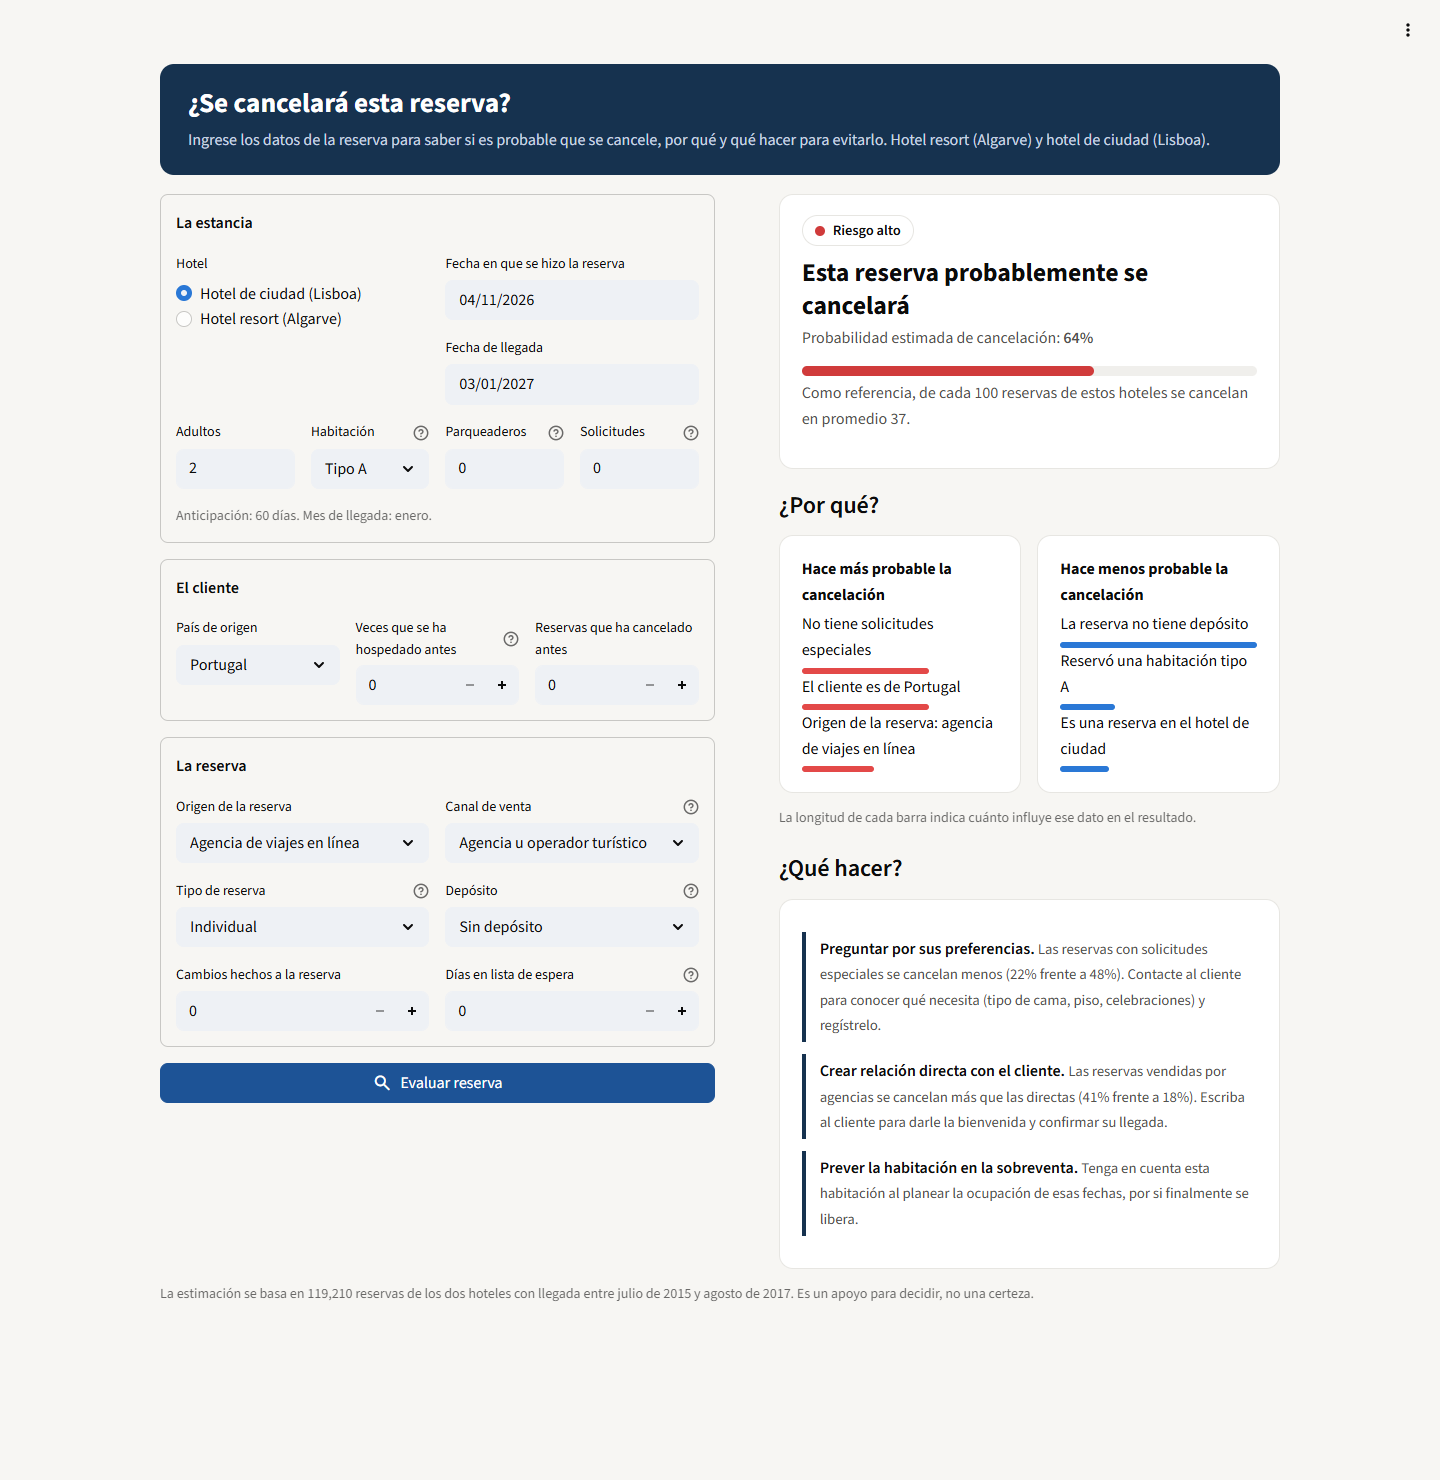

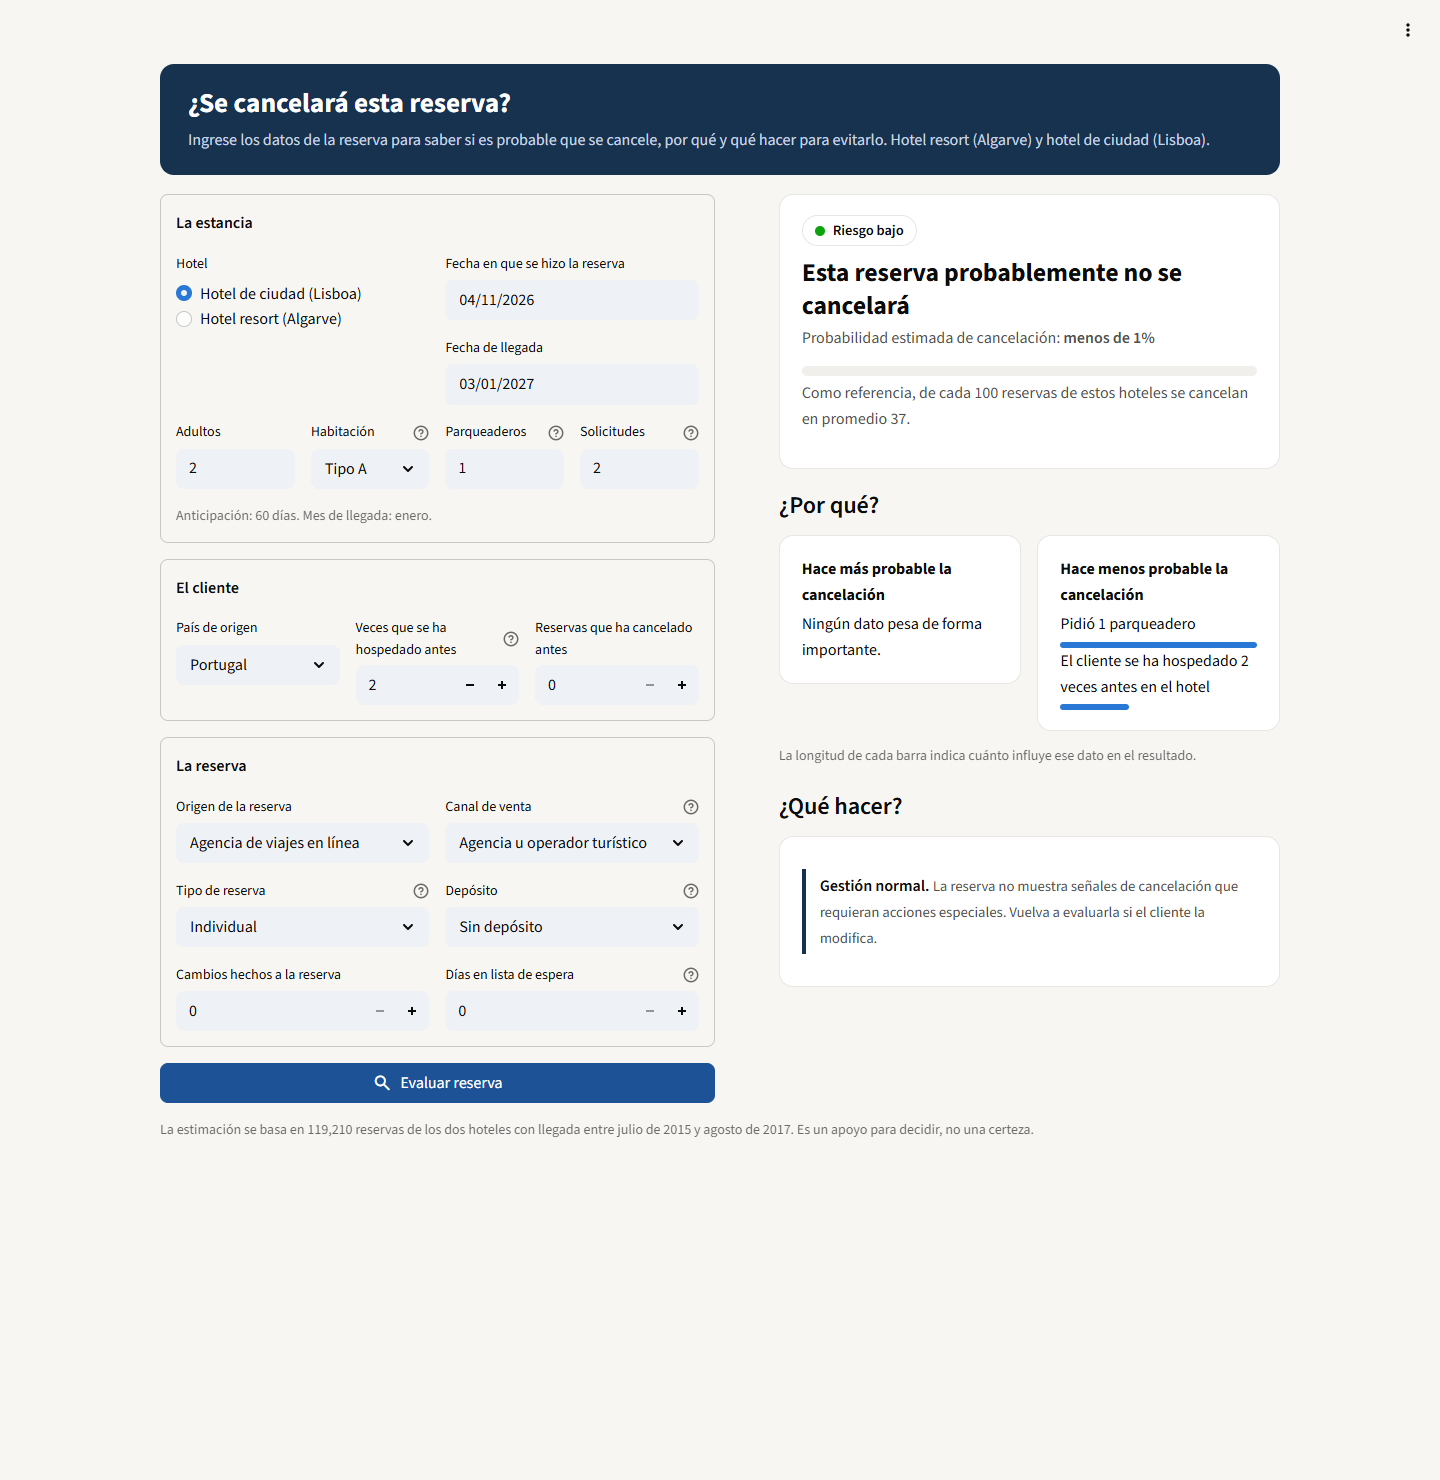

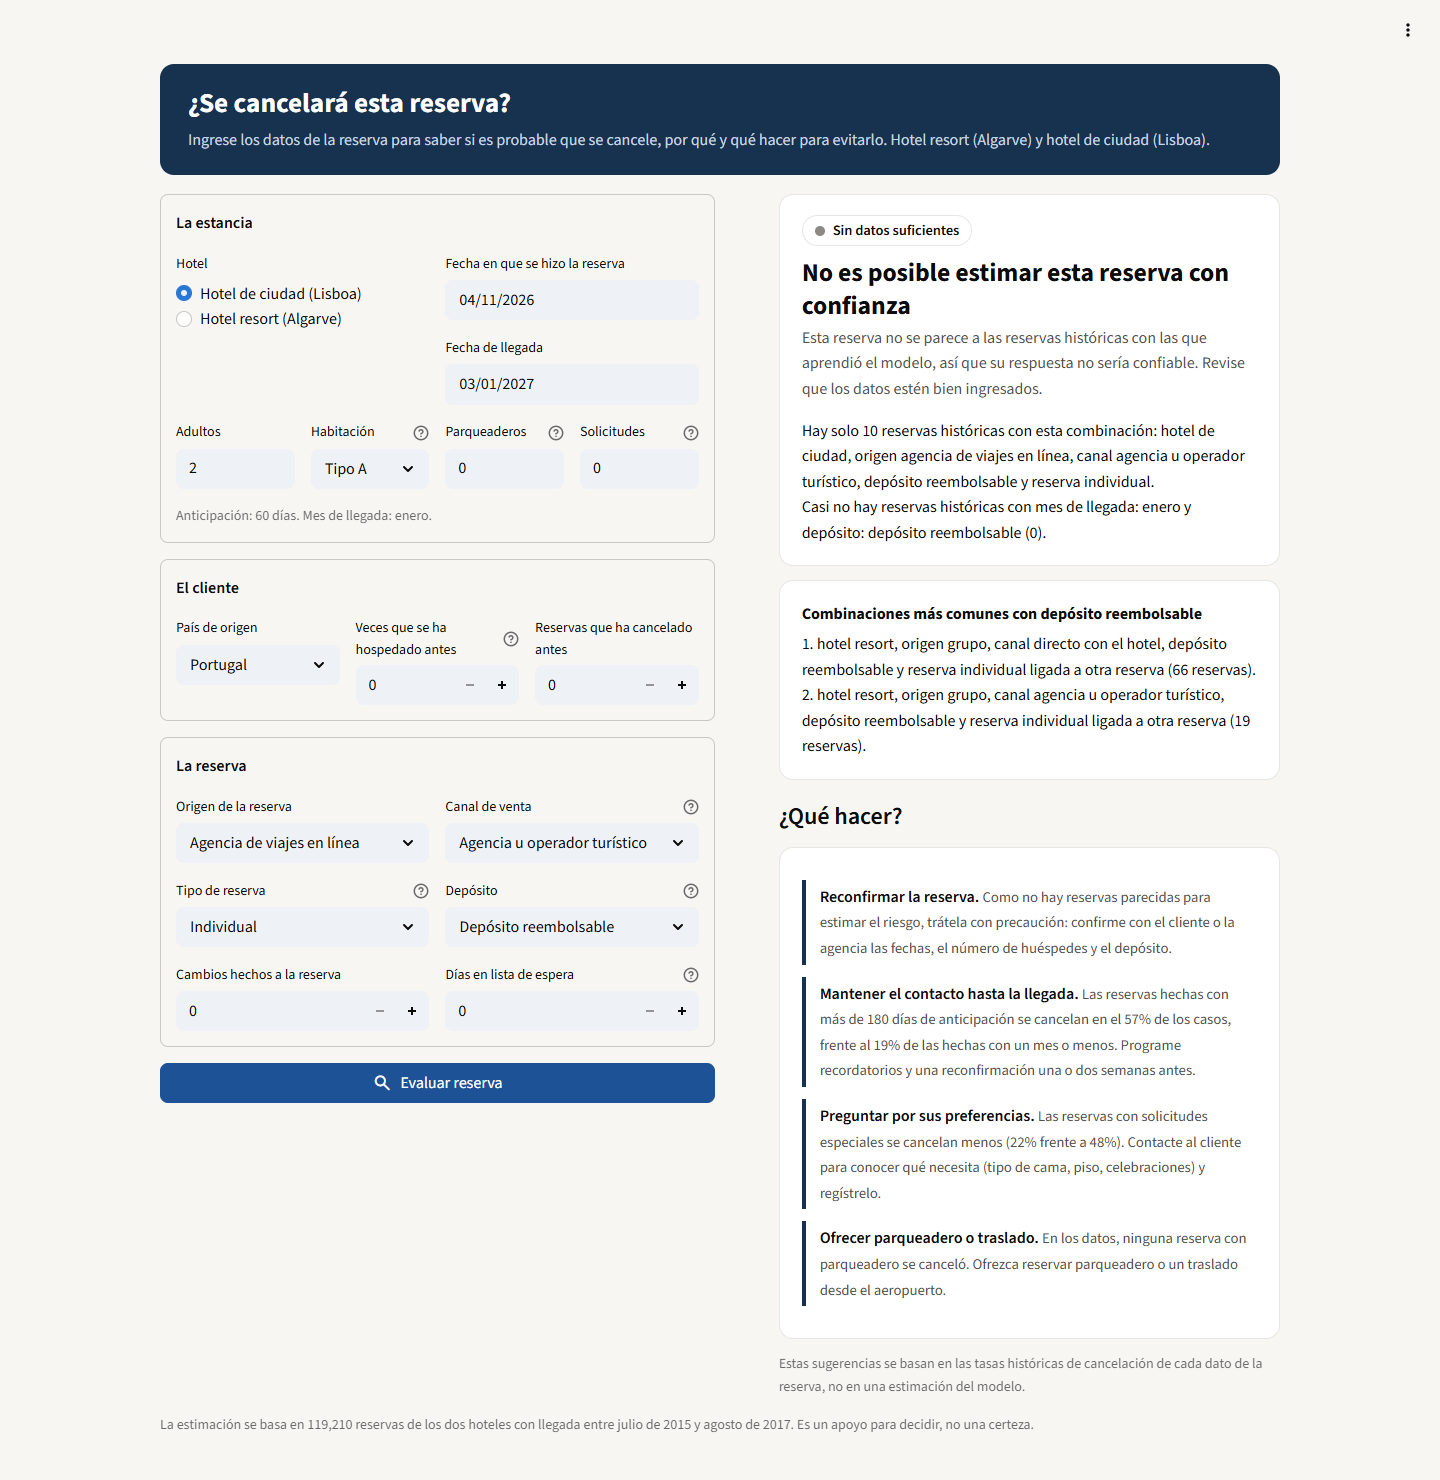

In [15]:
#Vista de la interfaz en funcionamiento: riesgo alto, riesgo bajo y reserva sin datos históricos suficientes
from IPython.display import Image, display
for captura in ['1_riesgo_alto', '2_riesgo_bajo', '3_sin_datos']:
    display(Image(filename=f'capturas_despliegue/{captura}.png', width=1100))

In [16]:
#Detener la interfaz (ejecutar al terminar de usarla)
proceso.terminate()
print("Interfaz detenida")

Interfaz detenida


# **FIN**